# Учебное исследование территории Ивангорода с помощью BlocksNet

Этот ноутбук шаг за шагом исследует город **Ивангород** (Ленинградская область) при помощи открытой библиотеки
**BlocksNet** (версия 1.0.0a9) и открытых данных **OpenStreetMap**.

Простым языком, мы:

1. скачаем границу города и уличную сеть из OpenStreetMap;
2. «нарежем» город на **кварталы** — небольшие участки, окружённые дорогами;
3. скачаем готовый **пешеходный граф** и посчитаем, сколько **минут пешком** идти от каждого квартала до каждого;
4. соберём данные о зданиях (и оценим население кварталов) и о школах;
5. посчитаем показатели: обеспеченность школами, плотность застройки, морфотипы, доступность территории;
6. сохраним всё в папку `examples/data/ivangorod` — при повторном запуске данные не скачиваются, а берутся из файлов.

**Разделы ноутбука:**

1. Настройки
2. Границы города
3. Дороги, железные дороги и вода
4. Нарезка кварталов
5. Типы использования кварталов (ленд-юз)
6. **🛑 Остановка перед расчётами** (важный момент — не пропустите!)
7. Пешеходный граф
8. Матрица времени в пути
9. Здания и население
10. Сервисы: школы
11. Показатели
12. Итоговый слой и проверка результатов
13. Повторный запуск и «если что-то не работает»


## Как пользоваться ноутбуком

- Запускайте ячейки **по порядку сверху вниз**: выделите ячейку и нажмите **Shift+Enter** (или треугольник «выполнить» слева от ячейки).
- **Первый запуск — самый долгий** (несколько минут): данные скачиваются из OpenStreetMap. Все последующие запуски быстрые, потому что готовые данные читаются из файлов.
- Менять код не нужно. Все файлы сохраняются автоматически в папку `data/ivangorod` рядом с ноутбуком. Если запустить ноутбук заново, он найдёт эти файлы и не станет скачивать данные повторно.
- Если где-то появится ошибка (красный текст) — не пугайтесь: в конце ноутбука есть раздел «Если что-то не работает».


## Раздел 1. Настройки

Первая ячейка загружает нужные библиотеки, создаёт папку для данных и результатов и настраивает
окружение для работы с интернетом: отключает помехи от «застрявших» прокси-настроек (например, после VPN)
и выбирает доступный сервер OpenStreetMap (Overpass) — главный сервер из России часто недоступен,
поэтому ноутбук сам проверяет зеркала и берёт первое рабочее.
Всё, что она печатает (версии программ и путь к папке), полезно для проверки.


In [1]:
%matplotlib inline

import os

# Готовим окружение для работы с интернетом. Бывает, что в системе «застревает» прокси-сервер
# (например, от VPN) — тогда соединения обрываются с ошибкой «Connection aborted». Строки ниже
# убирают прокси из окружения Python и запрещают библиотеке requests брать прокси из настроек Windows.
for var in ['HTTP_PROXY', 'HTTPS_PROXY', 'ALL_PROXY', 'http_proxy', 'https_proxy', 'all_proxy']:
    os.environ.pop(var, None)

import requests.utils
requests.utils.getproxies = lambda: {}

from pathlib import Path
import pickle
import importlib.metadata as md

import geopandas as gpd
import numpy as np
import osmnx as ox
import pandas as pd
import matplotlib.pyplot as plt

print('BlocksNet:', md.version('blocksnet'), '| IduEdu:', md.version('iduedu'), '| OSMnx:', md.version('osmnx'))

# --- Сервер OpenStreetMap (Overpass API) ---
# Главный сервер Overpass из России часто недоступен, а публичные зеркала бывают перегружены.
# Ноутбук проверяет зеркала по очереди и выбирает первое, которое отвечает прямо сейчас.
# Если со временем сервер перестанет работать — поменяйте порядок адресов в списке ниже.
overpass_mirrors = [
    'https://maps.mail.ru/osm/tools/overpass/api',  # Россия (VK) — быстрый, когда работает
    'https://overpass.private.coffee/api',          # Германия (бывший kumi.systems)
    'http://lz4.overpass-api.de/api',               # главный сервер (запасной вход по http)
    'https://overpass-api.de/api',                  # главный сервер
]

def pick_overpass_server(mirrors):
    """Проверяет зеркала Overpass по очереди и возвращает первое, которое отвечает."""
    probe = {'data': '[out:json][timeout:10];node(1);out;'}
    for base_url in mirrors:
        try:
            response = requests.post(
                base_url.rstrip('/') + '/interpreter',
                data=probe,
                timeout=40,
                headers={'User-Agent': 'Ivangorod-research-notebook/1.0'},
            )
            if response.status_code == 200 and '"elements"' in response.text:
                return base_url
        except Exception:
            continue
    return None

overpass_server = pick_overpass_server(overpass_mirrors)

if overpass_server is None:
    # Никто не ответил: у публичных серверов бывают «часы пик». Пробуем самый живучий вариант —
    # http://lz4.overpass-api.de (запасной вход главного сервера). При сбое повторы продолжит
    # делать функция osm_download из следующей ячейки.
    overpass_server = 'http://lz4.overpass-api.de/api'
    print('ВНИМАНИЕ: сейчас ни одно зеркало Overpass не отвечает (бывает в часы пик).')
    print('Пробуем через lz4.overpass-api.de. Если скачивание не пойдёт совсем — подождите')
    print('10–15 минут и запустите эту ячейку ещё раз.')

ox.settings.overpass_url = overpass_server
ox.settings.overpass_rate_limit = False  # запросов немного; паузы и проверки статуса не нужны

from iduedu import config as iduedu_config
iduedu_config.set_overpass_url(overpass_server.rstrip('/') + '/interpreter')
iduedu_config.set_timeout(120)

print('Сервер OpenStreetMap (Overpass):', overpass_server)

# Папка, куда сохраняются все скачанные данные и результаты расчётов
DATA_DIR = Path('data/ivangorod')
DATA_DIR.mkdir(parents=True, exist_ok=True)
print('Папка для данных и результатов:', DATA_DIR.resolve())


BlocksNet: 1.0.0a9 | IduEdu: 0.4.1 | OSMnx: 2.1.1
Сервер OpenStreetMap (Overpass): https://maps.mail.ru/osm/tools/overpass/api
Папка для данных и результатов: C:\Users\Diana\reprository\python-package-boilerplate\examples\data\ivangorod


Вторая ячейка — вспомогательные функции. Они нужны, чтобы работал главный приём ноутбука:
**«если файл уже есть — читаем его, если нет — скачиваем/считаем»** — это повторное использование данных.
Функция `osm_download` скачивает данные с автоматическими повторами: если сервер OSM подведёт,
она сама подождёт, попробует ещё раз и при необходимости переключится на другое зеркало.


In [2]:
import time

from iduedu import config as iduedu_config


def osm_download(fetch, attempts=4, pause_seconds=20):
    """Скачивает данные из OpenStreetMap с автоматическими повторами.

    Серверы Overpass бывают перегружены: запрос может не пройти с первого раза. Тогда функция
    ждёт и пробует снова — всего до 4 попыток. А если сервер перестал отвечать совсем, она
    переключается на другое зеркало из списка Раздела 1 и продолжает уже с него.
    """
    global overpass_server
    for attempt in range(1, attempts + 1):
        try:
            return fetch()
        except ox._errors.InsufficientResponseError:
            raise  # в данных OSM просто нет таких объектов — повторять бессмысленно
        except Exception as error:
            if attempt == attempts:
                raise
            print(f'Попытка {attempt} из {attempts} не удалась: {error}')
            new_server = pick_overpass_server([m for m in overpass_mirrors if m != overpass_server])
            if new_server is not None and new_server != overpass_server:
                overpass_server = new_server
                ox.settings.overpass_url = overpass_server
                iduedu_config.set_overpass_url(overpass_server.rstrip('/') + '/interpreter')
                print('Переключаюсь на другой сервер:', overpass_server)
            print(f'Ждём {pause_seconds} секунд и пробуем ещё раз...')
            time.sleep(pause_seconds)


def save_layer(layer, name, with_block_id=False):
    """Сохраняет слой (таблицу с геометрией) в файл GeoJSON в папке data/ivangorod.

    GeoJSON — стандартный формат для карт: его можно открыть в QGIS, на веб-карте и в других программах.
    Результат всегда сохраняется в системе координат EPSG:4326 (стандарт для GeoJSON).
    Параметр with_block_id=True добавляет колонку с номерами кварталов, чтобы при повторном
    чтении файла таблицы правильно совмещались друг с другом.
    """
    layer = layer.copy()
    if with_block_id:
        layer['block_id'] = layer.index.astype(int)
    layer = layer.reset_index(drop=True)
    path = DATA_DIR / f'{name}.geojson'
    layer.to_crs(4326).to_file(path, driver='GeoJSON', index=False)
    print('Сохранено:', path)


def load_layer(name):
    """Читает ранее сохранённый слой, если файл существует. Если файла нет — возвращает None,
    и ячейка, которая вызвала функцию, сама скачает данные из OpenStreetMap или посчитает результат заново."""
    path = DATA_DIR / f'{name}.geojson'
    if not path.exists():
        return None
    layer = gpd.read_file(path)
    if 'block_id' in layer.columns:
        layer = layer.set_index('block_id')
        layer.index.name = None
    print('Используем сохранённый файл (скачивание не нужно):', path)
    return layer


## Основные запросы

Все данные берутся из **OpenStreetMap** (openstreetmap.org, лицензия ODbL). Запросы идут через
**Overpass API**: в Разделе 1 ноутбук сам проверяет публичные зеркала Overpass
и использует первое доступное. Ответы сохраняются в `data/ivangorod/` —
при повторном запуске данные читаются из файлов и заново не скачиваются.

| Слой | Что запрашивается в OSM | Способ запроса |
|---|---|---|
| Граница города | объект «Ивангород, Ленинградская область, Россия» | OSMnx, поиск по названию (Nominatim) |
| Дороги | теги `highway` (жилые, магистральные, пешеходные, служебные и др.) и `service` | Overpass, `features_from_polygon` |
| Железные дороги | `railway=rail` | Overpass |
| Вода | `natural=water/bay`, `waterway=river/canal/ditch`, `water=lake`, `landuse=basin`, берега | Overpass |
| Землепользование | все полигоны `landuse` (жилые, промышленные, лес, кладбища и др.) | Overpass |
| Здания | `building=*`; этажность — `building:levels` | Overpass |
| Школы | `amenity=school` | Overpass |

**Источник данных:** OpenStreetMap, © участники OpenStreetMap (ODbL).
**Фактическая дата загрузки данных:** 16.10.2026.

Скачанные слои: `boundaries.geojson`, `roads.geojson`, `railways.geojson`, `water.geojson`,
`functional_zones.geojson`, `buildings_raw.geojson`, `schools_raw.geojson` — лежат в папке
`data/ivangorod/` рядом с ноутбуком. Пешеходный граф для расчёта времени в пути скачивается
отдельно в Разделе 6.


## Раздел 2. Границы города

Скачаем границу Ивангорода из OpenStreetMap по названию. Граница — это «рамка», внутри которой дальше
будет считаться всё исследование.

Ячейка ниже: если файл `boundaries.geojson` уже сохранён — он будет прочитан, иначе граница скачается
из OpenStreetMap. Карта покажет, что мы нашли. Площадь Ивангорода — примерно 7–8 км².


Используем сохранённый файл (скачивание не нужно): data\ivangorod\boundaries.geojson
Площадь территории по границе, км²: 68.2


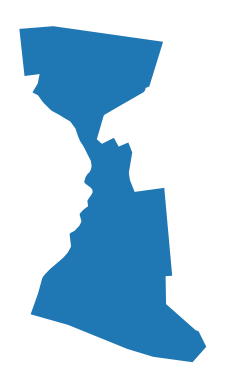

In [3]:
boundaries = load_layer('boundaries')

if boundaries is None:
    boundaries = osm_download(lambda: ox.geocode_to_gdf('Ивангород, Ленинградская область, Россия'))
    save_layer(boundaries, 'boundaries')

area_km2 = boundaries.to_crs(boundaries.estimate_utm_crs()).area.sum() / 1_000_000
print('Площадь территории по границе, км²:', round(area_km2, 1))
boundaries.plot().set_axis_off()
plt.show()


## Раздел 3. Дороги, железные дороги и вода

Чтобы поделить город на кварталы, нужны линии (дороги и железные дороги) и участки воды
(река Нарва и другие водоёмы). Скачаем их из OpenStreetMap по границе города — через зеркало Overpass,
которое ноутбук подобрал в Разделе 1 (главный сервер из России часто недоступен).

Набор тегов OSM ниже взят из учебного примера BlocksNet (`pipeline.ipynb`).


In [4]:
bc_tags = {
    'roads': {
        'highway': ['construction', 'crossing', 'living_street', 'motorway', 'motorway_link', 'motorway_junction',
                    'pedestrian', 'primary', 'primary_link', 'raceway', 'residential', 'road', 'secondary',
                    'secondary_link', 'services', 'tertiary', 'tertiary_link', 'track', 'trunk', 'trunk_link',
                    'turning_circle', 'turning_loop', 'unclassified'],
        'service': ['living_street', 'emergency_access'],
    },
    'railways': {
        'railway': 'rail',
    },
    'water': {
        'riverbank': True,
        'reservoir': True,
        'basin': True,
        'dock': True,
        'canal': True,
        'pond': True,
        'natural': ['water', 'bay'],
        'waterway': ['river', 'canal', 'ditch'],
        'landuse': 'basin',
        'water': 'lake',
    },
}


In [5]:
polygon_for_osm = boundaries.union_all()  # граница города одним полигоном — так уходит запрос к OpenStreetMap

water = load_layer('water')
if water is None:
    water = osm_download(lambda: ox.features_from_polygon(polygon_for_osm, bc_tags['water']))
    # reset_index убирает служебный «двухуровневый» индекс из данных OSM — так таблицу принимает BlocksNet.
    water = water[water.geom_type.isin(['Polygon', 'MultiPolygon', 'LineString', 'MultiLineString'])].reset_index(drop=True)
    save_layer(water, 'water')

roads = load_layer('roads')
if roads is None:
    roads = osm_download(lambda: ox.features_from_polygon(polygon_for_osm, bc_tags['roads']))
    roads = roads[roads.geom_type.isin(['LineString', 'MultiLineString'])].reset_index(drop=True)
    save_layer(roads, 'roads')

railways = load_layer('railways')
if railways is None:
    railways = osm_download(lambda: ox.features_from_polygon(polygon_for_osm, bc_tags['railways']))
    railways = railways[railways.geom_type.isin(['LineString', 'MultiLineString'])].reset_index(drop=True)
    save_layer(railways, 'railways')

print('Объектов: вода —', len(water), '| дороги —', len(roads), '| железные дороги —', len(railways))


Используем сохранённый файл (скачивание не нужно): data\ivangorod\water.geojson
Используем сохранённый файл (скачивание не нужно): data\ivangorod\roads.geojson
Используем сохранённый файл (скачивание не нужно): data\ivangorod\railways.geojson
Объектов: вода — 65 | дороги — 240 | железные дороги — 28


## Раздел 4. Нарезка кварталов

**Квартал** — это участок городской территории, окружённый дорогами (а также водой или железной дорогой).
BlocksNet автоматически «режет» город на такие кварталы. Дальше все измерения делаем по кварталам.

Сначала маленькая техническая ячейка: переводим координаты из градусов в метры — так точнее считаются
площади и расстояния. Затем — подготовка объектов и сама нарезка.


In [6]:
crs = boundaries.estimate_utm_crs()  # подходящая система координат «в метрах» для Ивангорода
print('Система координат для расчётов:', crs)

for gdf in [water, roads, railways, boundaries]:
    gdf.to_crs(crs, inplace=True)


Система координат для расчётов: EPSG:32635


In [7]:
from blocksnet.blocks.cutting import preprocess_urban_objects, cut_urban_blocks

# Страховка: если в таблицах остался «двухуровневый» индекс из данных OSM — сбрасываем его,
# иначе BlocksNet откажется их принимать.
roads = roads.reset_index(drop=True)
railways = railways.reset_index(drop=True)
water = water.reset_index(drop=True)

lines, polygons = preprocess_urban_objects(roads, railways, water)


c:\Users\Diana\reprository\python-package-boilerplate\.venv\Lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
2026-10-19 23:26:59.911 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:44 - Checking roads schema
2026-10-19 23:26:59.925 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:51 - Checking railways schema
2026-10-19 23:26:59.934 | INFO     | blocksnet.blocks.cutting.preprocessing.core:preprocess_urban_objects:58 - Checking water schema


Используем сохранённый файл (скачивание не нужно): data\ivangorod\blocks.geojson
Получилось кварталов: 113


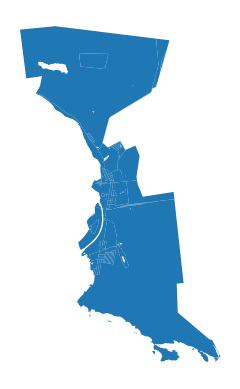

In [8]:
blocks = load_layer('blocks')

if blocks is None:
    blocks = cut_urban_blocks(boundaries, lines, polygons)
    save_layer(blocks, 'blocks', with_block_id=True)
else:
    blocks = blocks.to_crs(crs)

print('Получилось кварталов:', len(blocks))
blocks.plot().set_axis_off()
plt.show()


## Раздел 5. Тип использования кварталов (ленд-юз)

Каждому кварталу назначим «тип использования» на основе зон `landuse` из OpenStreetMap:
жилой, деловой, промышленный, рекреационный и т.д. Правила перевода зон в типы — как в учебном
примере BlocksNet.


In [9]:
functional_zones = load_layer('functional_zones')

if functional_zones is None:
    zones_osm = osm_download(lambda: ox.features_from_polygon(boundaries.to_crs(4326).union_all(), tags={'landuse': True}))
    functional_zones = zones_osm.reset_index(drop=True)[['geometry', 'landuse']]
    functional_zones = functional_zones.rename(columns={'landuse': 'functional_zone'})
    save_layer(functional_zones, 'functional_zones')

functional_zones = functional_zones.to_crs(crs)
functional_zones.head()


Используем сохранённый файл (скачивание не нужно): data\ivangorod\functional_zones.geojson


,functional_zone,geometry
0,construction,"POLYGON ((568512.588 6582593.289, 568510.454 6..."
1,industrial,"POLYGON ((567992.271 6580051.061, 568046.58 65..."
2,quarry,"POLYGON ((565627.995 6587995.918, 565602.065 6..."
3,forest,"POLYGON ((569273.542 6581641.108, 569273.333 6..."
4,industrial,"POLYGON ((568793.876 6581602.73, 568772.066 65..."


In [10]:
from blocksnet.enums import LandUse

rules = {
    'commercial': LandUse.BUSINESS,
    'industrial': LandUse.INDUSTRIAL,
    'cemetery': LandUse.SPECIAL,
    'garages': LandUse.INDUSTRIAL,
    'residential': LandUse.RESIDENTIAL,
    'retail': LandUse.BUSINESS,
    'grass': LandUse.RECREATION,
    'farmland': LandUse.AGRICULTURE,
    'construction': LandUse.SPECIAL,
    'brownfield': LandUse.INDUSTRIAL,
    'forest': LandUse.RECREATION,
    'recreation_ground': LandUse.RECREATION,
    'religious': LandUse.SPECIAL,
    'flowerbed': LandUse.RECREATION,
    'military': LandUse.SPECIAL,
    'landfill': LandUse.TRANSPORT,
}


Используем сохранённый файл (скачивание не нужно): data\ivangorod\blocks_landuse.geojson


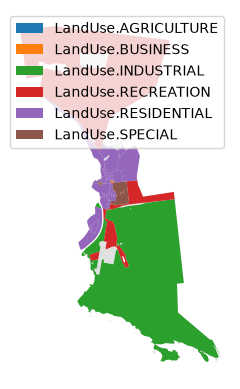

In [11]:
from blocksnet.blocks.assignment import assign_land_use

blocks_from_file = load_layer('blocks_landuse')
if blocks_from_file is not None:
    blocks = blocks_from_file.to_crs(crs)
else:
    blocks = assign_land_use(blocks, functional_zones.reset_index(drop=True), rules)
    save_layer(blocks, 'blocks_landuse', with_block_id=True)

ax = blocks.plot(color='#ddd')
blocks.plot(column='land_use', legend=True, ax=ax)
ax.set_axis_off()
plt.show()


---

# 🛑 ОСТАНОВКА ПЕРЕД РАСЧЁТАМИ

**Кварталы подготовлены.** Вы нарезали город на кварталы и назначили им тип использования — это «фундамент» исследования.

Дальше начинаются **расчёты**:

- время в пути между кварталами (пешеходный граф);
- население кварталов (по зданиям) и школы;
- показатели: обеспеченность школами, плотность, морфотипы, доступность территории.

**Прежде чем продолжать:** уточните, какие показатели вам нужны в итоговом отчёте. Ячейки ниже посчитают
всё, что есть в учебном примере `pipeline.ipynb` библиотеки BlocksNet. Если нужен другой или сокращённый
набор — скажите, и мы поправим ноутбук.

**Готовы? Продолжайте запускать ячейки по порядку.**

---


## Раздел 6. Пешеходный граф и время в пути

**Что такое граф.** Это схема дорожек и перекрёстков: точки (перекрёстки) соединены отрезками путей.
У каждого отрезка есть длина (метры) и время прохода (минуты).

**Что скачиваем.** Готовый **пешеходный граф** из **OpenStreetMap**: библиотека BlocksNet получает данные
из OpenStreetMap автоматически (через встроенный модуль IduEdu) и сама считает время каждого отрезка
по его длине и средней скорости пешехода — по умолчанию это **5 км/ч** (значение задано в настройках библиотеки IduEdu). Время хранится в колонке `time_min` — **в минутах**.

**Способ передвижения — пешком.** Интермодальный граф (с общественным транспортом) в этом исследовании
не строим. Если понадобится вариант «на автомобиле» — в конце ноутбука есть инструкция, как поменять один параметр.

Граф скачивается для области чуть больше границы города (выпуклая оболочка границы) — так пути на окраинах корректно соединяются.


In [12]:
from blocksnet.relations import get_accessibility_graph

graph_file = DATA_DIR / 'graph_walk.pickle'

if graph_file.exists():
    with open(graph_file, 'rb') as f:
        graph = pickle.load(f)
    print('Граф загружен из сохранённого файла:', graph_file)
else:
    graph = get_accessibility_graph(boundaries, 'walk')
    with open(graph_file, 'wb') as f:
        pickle.dump(graph, f)
    print('Пешеходный граф скачан из OpenStreetMap и сохранён:', graph_file)

print('Перекрёстков (узлов):', graph.number_of_nodes())
print('Отрезков путей (рёбер):', graph.number_of_edges())


Граф загружен из сохранённого файла: data\ivangorod\graph_walk.pickle
Перекрёстков (узлов): 7275
Отрезков путей (рёбер): 21008


Сохраним рёбра графа отдельным файлом GeoJSON — их будет удобно показывать на карте
(в том числе на будущем HTML-дашборде). И нарисуем общую картину пешеходных путей.


Используем сохранённый файл (скачивание не нужно): data\ivangorod\graph_walk_edges.geojson


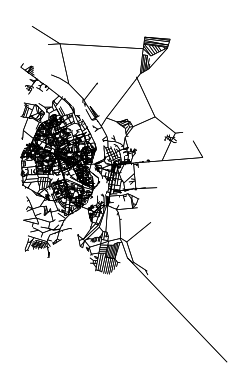

In [13]:
from shapely.geometry import LineString

edges_gdf = load_layer('graph_walk_edges')

if edges_gdf is None:
    rows = []
    for u, v, data in graph.edges(data=True):
        rows.append({
            'time_min': data.get('time_min'),
            'length_meter': data.get('length_meter'),
            'geometry': LineString([
                (graph.nodes[u]['x'], graph.nodes[u]['y']),
                (graph.nodes[v]['x'], graph.nodes[v]['y']),
            ]),
        })
    edges_gdf = gpd.GeoDataFrame(rows, crs=graph.graph['crs'])
    save_layer(edges_gdf, 'graph_walk_edges')

edges_gdf.plot(linewidth=0.5, color='black').set_axis_off()
plt.show()


In [14]:
edge_times = edges_gdf['time_min']
edge_lengths = edges_gdf['length_meter']

print('Медианное время одного отрезка, мин:', round(edge_times.median(), 2))
print('Общая длина пешеходных путей, км:', round(edge_lengths.sum() / 1000, 1))
if edge_times.sum() > 0:
    speed_kmh = edge_lengths.sum() / 1000 / (edge_times.sum() / 60)
    print('Средняя скорость, заложенная в графе, км/ч:', round(speed_kmh, 1))


Медианное время одного отрезка, мин: 0.34
Общая длина пешеходных путей, км: 1120.1
Средняя скорость, заложенная в графе, км/ч: 5.0


## Раздел 7. Матрица времени в пути между кварталами

**Матрица доступности** — это таблица размера «кварталы × кварталы», в которой записано, сколько минут
идти от одного квартала до другого (по пешеходным путям). На диагонали — нули (от квартала к нему самому).
Значения считаются от «центральной точки» каждого квартала.

Матрицу сохраняем в два файла: `acc_mx.parquet` (для повторного использования программой) и `acc_mx.csv`
(чтобы можно было открыть таблицу и посмотреть глазами). В GeoJSON матрицу сохранить нельзя:
GeoJSON — формат для карт, а матрица — просто таблица чисел.


In [15]:
from blocksnet.relations import calculate_accessibility_matrix

mx_file = DATA_DIR / 'acc_mx.parquet'

if mx_file.exists():
    acc_mx = pd.read_parquet(mx_file)
    print('Матрица загружена из сохранённого файла:', mx_file)
else:
    acc_mx = calculate_accessibility_matrix(blocks, graph)
    acc_mx.to_parquet(mx_file)
    acc_mx.to_csv(DATA_DIR / 'acc_mx.csv')
    print('Матрица рассчитана и сохранена:', mx_file)

acc_mx.iloc[:5, :5]


Матрица загружена из сохранённого файла: data\ivangorod\acc_mx.parquet


c:\Users\Diana\reprository\python-package-boilerplate\.venv\Lib\site-packages\pandas\io\formats\format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,0,1,2,3,4
0,0.000000,19.281250,59.3750,15.109375,14.523438
1,19.281250,0.000000,47.6875,8.445312,7.867188
2,59.375000,47.687500,0.0000,46.375000,46.750000
3,15.109375,8.445312,46.3750,0.000000,2.318359
4,14.523438,7.867188,46.7500,2.318359,0.000000


In [16]:
values = acc_mx.to_numpy().astype(float)
mask = np.isfinite(values) & (values > 0)

print('Пар «квартал → квартал»:', int(mask.sum()))
print('Медианное время в пути, мин:', round(float(np.median(values[mask])), 1))
print('Максимальное время в пути, мин:', round(float(values[mask].max()), 1))


Пар «квартал → квартал»: 12580
Медианное время в пути, мин: 39.9
Максимальное время в пути, мин: 235.9


## Раздел 8. Здания и население

Скачаем контуры зданий из OpenStreetMap и определим:

- **жилое** ли здание (колонка `is_living`);
- **число этажей** (колонка `building:levels` в OSM).

Затем библиотека восстанавливает отсутствующие сведения (например, площадь квартир) и оценивает
**население** каждого здания и квартала. Оценка приблизительная — по открытым данным.


Используем сохранённый файл (скачивание не нужно): data\ivangorod\buildings_raw.geojson
Зданий скачано: 1185


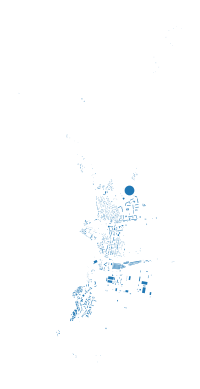

In [17]:
buildings_raw = load_layer('buildings_raw')

if buildings_raw is None:
    buildings_raw = osm_download(lambda: ox.features_from_polygon(boundaries.to_crs(4326).union_all(), tags={'building': True}))
    buildings_raw = buildings_raw.reset_index(drop=True).to_crs(crs)

    is_living_tags = ['residential', 'house', 'apartments', 'detached', 'terrace', 'dormitory']
    buildings_raw['is_living'] = buildings_raw['building'].apply(lambda b: b in is_living_tags)
    if 'building:levels' in buildings_raw.columns:
        buildings_raw['number_of_floors'] = pd.to_numeric(buildings_raw['building:levels'], errors='coerce')
    else:
        buildings_raw['number_of_floors'] = np.nan

    save_layer(buildings_raw, 'buildings_raw')
else:
    buildings_raw = buildings_raw.to_crs(crs)

print('Зданий скачано:', len(buildings_raw))
buildings_raw.plot().set_axis_off()
plt.show()


Используем сохранённый файл (скачивание не нужно): data\ivangorod\buildings_blocks.geojson
Суммарное население по расчёту, чел.: 7689


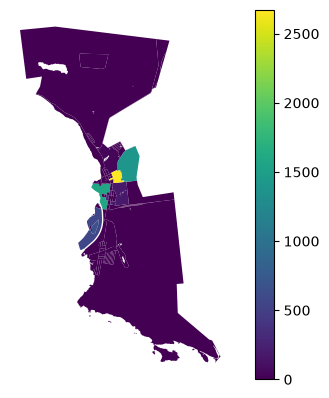

In [18]:
from blocksnet.blocks.aggregation import aggregate_objects
from blocksnet.preprocessing.imputing import impute_buildings

buildings_blocks = load_layer('buildings_blocks')

if buildings_blocks is None:
    buildings = impute_buildings(buildings_raw, default_living_demand=30)
    buildings_blocks = aggregate_objects(blocks, buildings)[0]
    save_layer(buildings_blocks, 'buildings_blocks', with_block_id=True)
else:
    buildings_blocks = buildings_blocks.to_crs(crs)

print('Суммарное население по расчёту, чел.:', int(round(buildings_blocks['population'].sum())))
buildings_blocks.plot('population', legend=True).set_axis_off()
plt.show()


## Раздел 9. Сервисы: школы

Как пример сервиса возьмём **школы** (тег `amenity=school` в OpenStreetMap). Библиотека восстановит
пропущенные сведения (например, вместимость) и посчитает суммарную вместимость школ по кварталам.


Используем сохранённый файл (скачивание не нужно): data\ivangorod\schools_blocks.geojson
Суммарная вместимость школ, мест: 1000


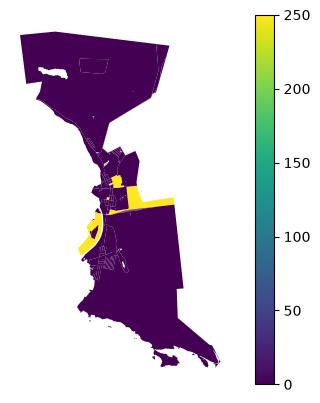

In [19]:
from blocksnet.preprocessing.imputing import impute_services

schools_blocks = load_layer('schools_blocks')

if schools_blocks is None:
    schools = load_layer('schools_raw')
    if schools is None:
        schools = osm_download(lambda: ox.features_from_polygon(boundaries.to_crs(4326).union_all(), tags={'amenity': 'school'}))
        schools = schools.reset_index(drop=True).to_crs(crs)
        save_layer(schools, 'schools_raw')
    else:
        schools = schools.to_crs(crs)

    schools = impute_services(schools, 'school')
    schools_blocks = aggregate_objects(blocks, schools)[0]
    save_layer(schools_blocks, 'schools_blocks', with_block_id=True)
else:
    schools_blocks = schools_blocks.to_crs(crs)

print('Суммарная вместимость школ, мест:', round(schools_blocks['capacity'].sum()))
schools_blocks.plot('capacity', legend=True).set_axis_off()
plt.show()


## Раздел 10. Показатели

Теперь посчитаем показатели — это и есть «результаты исследования»:

1. **Обеспеченность школами** — сколько мест в школах приходится на жителей, с учётом конкуренции между кварталами (нормативы библиотеки; значение от 0 до 1).
2. **Показатели плотности** — по зданиям внутри кварталов.
3. **Морфотипы застройки** — тип городской среды по двум методикам (Spacematrix и Strelka).
4. **Доступность территории** — как быстро в среднем можно добраться от квартала до остальных.

Это полный набор из учебного примера `pipeline`. Если нужен другой набор метрик — скажите, добавим или уберём.


In [20]:
from blocksnet.analysis.provision import competitive_provision
from blocksnet.config import service_types_config

df = buildings_blocks[['population']].join(schools_blocks[['capacity']])
_, demand, accessibility = service_types_config['school'].values()
print('Норматив спроса (мест на человека):', demand, '| Нормативная доступность, мин:', accessibility)

prov_df, links_df = competitive_provision(df, acc_mx, accessibility, demand)

prov_df.to_csv(DATA_DIR / 'provision_school.csv')
links_df.to_csv(DATA_DIR / 'provision_school_links.csv')
prov_df.head()


2026-10-19 23:27:04.414 | INFO     | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:29 - Initializing provision DataFrame
2026-10-19 23:27:04.414 | WARNING  | blocksnet.analysis.provision.competitive.core:_initialize_provision_df:33 - No demand in columns. Imputing using population column and demand parameter
2026-10-19 23:27:04.428 | INFO     | blocksnet.analysis.provision.competitive.core:_supply_self:56 - Supplying blocks with own capacities
2026-10-19 23:27:04.428 | INFO     | blocksnet.analysis.provision.competitive.core:competitive_provision:190 - Setting and solving LP problems until max depth or break condition reached


Норматив спроса (мест на человека): 120 | Нормативная доступность, мин: 15


2026-10-19 23:27:05.020 | SUCCESS  | blocksnet.analysis.provision.competitive.core:competitive_provision:203 - Provision assessment finished


,demand,capacity,demand_left,demand_within,demand_without,capacity_left,capacity_within,capacity_without,provision_strong,provision_weak
0,189,0,0,189,0,0,0,0,1.0,1.0
1,0,0,0,0,0,0,0,0,NaN,NaN
2,1,0,1,0,0,0,0,0,0.0,0.0
3,0,0,0,0,0,0,0,0,NaN,NaN
4,0,0,0,0,0,0,0,0,NaN,NaN


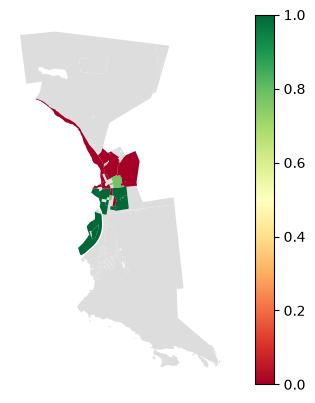

In [21]:
ax = blocks.plot(color='#ddd')
blocks.join(prov_df).plot('provision_strong', ax=ax, cmap='RdYlGn', vmin=0, vmax=1, legend=True)
ax.set_axis_off()
plt.show()


In [22]:
from blocksnet.analysis.indicators import calculate_density_indicators

buildings_blocks['site_area'] = buildings_blocks.area
density_df = calculate_density_indicators(buildings_blocks)
density_df.head()


,site_area,footprint_area,build_floor_area,living_area,non_living_area,fsi,gsi,mxi,l,osr,share_living,share_non_living
0,493856.833834,38468.384610,84634.789902,47252.535783,37382.254119,0.171375,0.077894,0.558311,2.200113,5.380630,1.228347,0.971766
1,10774.460042,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN
2,820827.230720,16608.499593,17436.724938,284.518768,17152.206170,0.021243,0.020234,0.016317,1.049868,46.122121,0.017131,1.032737
3,14630.129967,2558.356379,3281.419606,0.000000,3281.419606,0.224292,0.174869,0.000000,1.282628,3.678827,0.000000,1.282628
4,1355.475904,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,inf,NaN,NaN


In [23]:
from blocksnet.analysis.morphotypes import get_spacematrix_morphotypes, get_strelka_morphotypes

spacematrix_df, spacematrix_clusters = get_spacematrix_morphotypes(density_df)
spacematrix_df.head()


,l,fsi,mxi,cluster,morphotype
0,2.200113,0.171375,0.558311,6.0,low-rise low-density residential
1,0.000000,0.000000,0.000000,NaN,NaN
2,1.049868,0.021243,0.016317,2.0,low-rise low-density non-residential
3,1.282628,0.224292,0.000000,10.0,low-rise low-density non-residential
4,0.000000,0.000000,0.000000,NaN,NaN


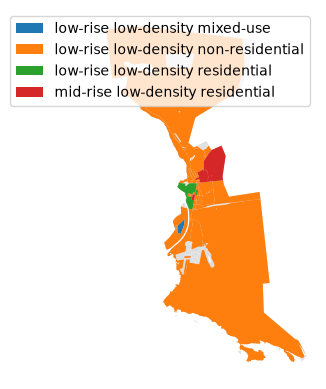

In [24]:
ax = blocks.plot(color='#ddd')
blocks.join(spacematrix_df).plot('morphotype', legend=True, ax=ax)
ax.set_axis_off()
plt.show()


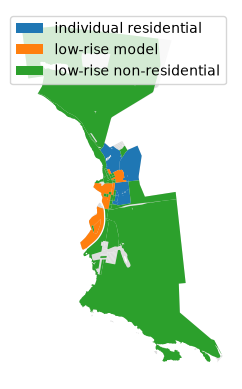

In [25]:
strelka_df = get_strelka_morphotypes(density_df)

ax = blocks.plot(color='#ddd')
blocks.join(strelka_df).plot('morphotype', legend=True, ax=ax)
ax.set_axis_off()
plt.show()


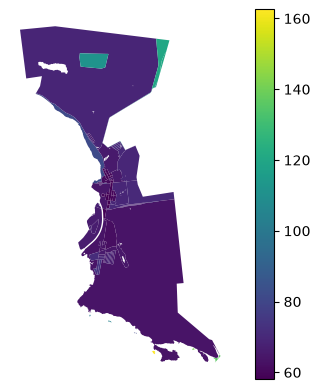

In [26]:
from blocksnet.analysis.network.accessibility import area_accessibility

area_acc = area_accessibility(acc_mx, buildings_blocks)
blocks.join(area_acc).plot('area_accessibility', legend=True).set_axis_off()
plt.show()


## Раздел 11. Итог: единый слой показателей

Собираем все показатели в одну таблицу-слой и сохраняем в `blocks_results.geojson`.
Этот файл станет основой для будущей интерактивной HTML-карты с дашбордом.


In [27]:
results = blocks.copy()
results = results.join(buildings_blocks[['population']])
results = results.join(prov_df)
results = results.join(spacematrix_df[['morphotype']].rename(columns={'morphotype': 'morphotype_spacematrix'}))
results = results.join(strelka_df[['morphotype']].rename(columns={'morphotype': 'morphotype_strelka'}))
results = results.join(area_acc)
results = results.join(density_df.add_prefix('density_'))

save_layer(results, 'blocks_results', with_block_id=True)

summary = pd.Series({
    'Кварталов': len(results),
    'Население, чел.': int(round(results['population'].sum())),
    'Средняя обеспеченность школами (0…1)': round(results['provision_strong'].mean(), 2),
    'Средняя доступность территории, мин': round(results['area_accessibility'].mean(), 1),
})
summary


Сохранено: data\ivangorod\blocks_results.geojson


c:\Users\Diana\reprository\python-package-boilerplate\.venv\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: NaN of Infinity value found. Skipped. Further messages of this type will be suppressed.
  ogr_write(


Кварталов                                113.00
Население, чел.                         7689.00
Средняя обеспеченность школами (0…1)       0.44
Средняя доступность территории, мин       70.30
dtype: float64

## Раздел 12. Проверка результатов

Пробегитесь по списку — всё ли похоже на правду:

- ✅ **Границы** (Раздел 2): полигон похож на Ивангород; площадь примерно 7–8 км².
- ✅ **Кварталы** (Раздел 4): визуально совпадают с уличной сетью; всего их десятки–сотни.
- ✅ **Ленд-юз** (Раздел 5): кварталы раскрашены по типам использования, легенда читаема.
- ✅ **Граф** (Раздел 6): рёбер больше, чем узлов; медианное время отрезка — единицы минут.
- ✅ **Матрица** (Раздел 7): медианное время в пути разумно для малого города (обычно меньше 30 минут).
- ✅ **Население** (Раздел 8): суммарно порядка 9–10 тысяч человек (оценка по OSM; официальные данные ≈ 9,3 тыс.).
- ✅ **Школы** (Раздел 9): школы на карте стоят там, где школы в реальности.
- ✅ **Показатели** (Разделы 10–11): обеспеченность в диапазоне 0…1; морфотипы и доступность отображаются на картах.
- ✅ **Файлы**: в `examples/data/ivangorod/` лежат все GeoJSON, `acc_mx.parquet`, `acc_mx.csv`, граф и сводные CSV.

Если какой-то пункт выглядит странно — напишите номер раздела, и мы разберёмся.


## Раздел 13. Повторный запуск и «если что-то не работает»

### Как запустить ноутбук заново

1. Откройте ноутбук (в VS Code или в Jupyter).
2. Выберите меню **Kernel → Restart Kernel and Run All** (в VS Code — **Restart**, затем **Run All**).
3. Повторные запуски быстрые: все данные уже лежат в папке `examples/data/ivangorod` и не скачиваются повторно.

### Как обновить данные

Удалите нужный файл из `examples/data/ivangorod` (например, `roads.geojson`) и запустите ноутбук заново —
этот слой скачается свежий. Чтобы начать «с чистого листа», удалите всю папку `examples/data/ivangorod`.

### Если что-то не работает

- **Ошибка при скачивании (timeout, 429, 504, SSL)** — главный сервер Overpass (overpass-api.de) из России часто
  недоступен, а зеркала бывают перегружены. Ноутбук сам выбирает рабочее зеркало (Раздел 1), повторяет попытки
  до 4 раз и отключает помехи от прокси. Если ошибка всё же появилась — подождите 10–15 минут и запустите
  ячейку ещё раз: уже скачанное сохраняется и повторно не скачивается.
- **Хотите сменить сервер скачивания вручную** — в Разделе 1 переставьте адреса в списке `overpass_mirrors`:
  будет использоваться первый рабочий адрес из списка. Это публичные зеркала Overpass —
  если одно не отвечает, ноутбук пробует следующее.
- **Нашли не тот город** — в Разделе 2 замените строку запроса, например на `'Ivangorod, Leningrad Oblast, Russia'`,
  удалите файл `boundaries.geojson` и запустите раздел заново.
- **Пустой слой** (например, железные дороги) — это нормально, если их нет в данных OSM. Расчёт продолжится.
- **Красная ошибка в середине** — не запускайте ячейки ниже наугад: скопируйте текст ошибки и покажите нам.

### Как посчитать «на автомобиле» вместо «пешком» (по желанию)

1. В Разделе 6 в строке `graph = get_accessibility_graph(boundaries, 'walk')` замените `'walk'` на `'drive'`,
   а имя файла `graph_walk.pickle` — на `graph_drive.pickle` (в двух местах: чтение и запись).
2. Удалите файлы `acc_mx.parquet` и `acc_mx.csv` — матрица пересчитается по дорожной сети.
3. Запустите ноутбук заново.

### Что дальше

Позже мы соберём из этих результатов **одну HTML-страницу**: интерактивную карту города с показателями,
графиками и таблицами (отдельным файлом, на основе `blocks_results.geojson`).


---

## Приложение. Словарь показателей

Этот раздел — **справочник**: простыми словами объясняет все показатели, которые встречаются в ноутбуке
и в библиотеке BlocksNet. Запускать здесь нечего — это просто текст.

Все числа, которые упоминаются ниже, уже посчитаны в Разделах 4–11 и лежат в файле
`examples/data/ivangorod/blocks_results.geojson`.

**Мини-шпаргалка по единицам измерения:**

| Единица | Что значит |
|---|---|
| **м²** | квадратный метр (10 000 м² = 1 га) |
| **чел.** | человек |
| **места** | единица вместимости сервиса (школьные места, койки и т. п.) |
| **мин** | минуты пешей ходьбы (в нашем расчёте скорость 5 км/ч) |
| **доля 0…1** | простое отношение: 0 — «нет/ничего», 1 — «всё/полностью»; умножить на 100 = проценты |
| **м²/м²** | сколько «квадратов» чего-то приходится на 1 м² территории (тоже просто отношение) |


## Какие метрики есть в BlocksNet (обзор библиотеки)

Учебный пример `pipeline.ipynb` использует только часть возможностей библиотеки. Вот полная картина —
по группам.

### Плотность и застройка

- **FSI** (`fsi`) — плотность застройки: площадь зданий по всем этажам делится на площадь квартала.
  Единица — м²/м². FSI = 1 значит: если все этажи «расплющить» в один, здания займут весь квартал.
- **GSI** (`gsi`) — застроенность: какую часть квартала занимают «пятна» зданий (вид сверху). Доля 0…1.
- **MXI** (`mxi`) — «жилость»: доля жилых площадей среди всех площадей зданий. Доля 0…1.
- **L** (`l`) — средняя этажность зданий квартала: все этажи делятся на «пятно» застройки.
  Безразмерная, по смыслу — «этажи».
- **OSR** (`osr`) — сколько свободной (незастроенной) земли приходится на 1 м² зданий.
  Единица — м²/м²: больше — просторнее.
- **share_living** и **share_non_living** — служебные отношения: жилая и нежилая площадь на 1 м² застройки.
- **Основные площади** (все в м²): `site_area` — квартал, `footprint_area` — пятна зданий,
  `build_floor_area` — все этажи всех зданий, `living_area` — жилая, `non_living_area` — нежилая.

### Землепользование (тип использования территории)

- **`land_use`** — категория квартала: жилой (residential), деловой (business), промышленный (industrial),
  рекреационный, то есть зелёный (recreation), сельскохозяйственный (agriculture), специальный (special),
  транспортный (transport).
- **Доли зон** — какая часть площади квартала занята зонами каждого типа (0…1).
- Дополнительно библиотека умеет сравнивать кварталы по «похожести» их состава (similarity, 0…1)
  и предсказывать тип кварталов моделью машинного обучения.

### Доступность (сколько минут куда идти)

- **Матрица доступности** — таблица «каждый квартал × каждый квартал»: время пешком между ними, в минутах.
  Считается от «центральной точки» квартала.
- **median / mean / max accessibility** — по строке матрицы: медианное, среднее и максимальное время
  от квартала до всех остальных (мин).
- **area_accessibility** — среднее время до остальных кварталов, взвешенное по их площади (мин).
- **relative_accessibility** — «профиль» одного квартала: сколько минут от него до каждого другого (мин).
- **land_use_accessibility** — сколько минут до кварталов заданного типа, например «до зелёных зон» (мин).
- **connectivity** — «достижимость»: 1 делится на время (единица 1/мин). Чем больше, тем ближе всё вокруг.

### Сервисы (школы, поликлиники, магазины…)

- **services_count** — сколько сервисов каждого типа в квартале (штук).
- **services_density** — плотность сервисов: количество на м² территории (шт./м²).
- **shannon_diversity** — разнообразие сервисов (индекс Шеннона, безразмерный): 0 — пусто или один тип;
  чем больше, тем больше разных типов.
- **services_collocation** — как часто разные сервисы встречаются в одном квартале (0…1).
- В библиотеке заложены нормативы для **82 типов сервисов**. Например, школа: 120 мест на 1000 жителей
  и 15 минут пешком; детсад: 61 и 7; поликлиника: 13 и 15; аптека: 15 и 15; магазин у дома: 200 и 10;
  парк: 150 и 30.

### Обеспеченность (хватает ли сервисов)

- **Конкурентная обеспеченность** (`competitive_provision`) — главные показатели: `demand` (потребность,
  мест), `capacity` (вместимость, мест), `provision_strong` (доля потребности, закрытая по нормативу, 0…1),
  `provision_weak` (то же, но с учётом и более далёких сервисов, 0…1), `links` — таблица «кто куда идёт»
  (потоки, в местах).
- **Простая обеспеченность** (`shared`) — `provision` (доля людей в зоне доступности, 0…1), `load`
  (нагрузка на сервисы), `capacity_within` и `population_within` (мест и людей в зоне доступности).

### Центральность

- **population_centrality** (0…1) — где живёт много людей и при этом квартал хорошо связан с соседями.
- **services_centrality** (0…1) — комбинация связности, разнообразия и плотности сервисов.

### Морфотипы (типы застройки)

- **spacematrix** — машинная кластеризация: похожие кварталы группируются по комплекту показателей
  (этажность L, плотность FSI, «жилость» MXI); результат — текстовое описание, например
  «low-rise low-density residential» (малоэтажный, низкой плотности, жилой).
- **strelka** — классификация по правилам: high-rise / mid-rise / low-rise и подтипы
  (микрорайон, квартал, ИЖС и т. п.).

### Сеть и транспорт

- **origin_destination** — матрица корреспонденций: сколько людей «тянется» из квартала в квартал (чел.).
- **road_congestion** — загруженность дорог: по кратчайшим путям суммируются потоки; у каждого участка
  дороги получается число «поездок».
- **NetworkClassifier** — классификация населённого пункта по графу моделью (город / пригород / деревня).

### Свободные территории (vacant_area)

- **area** — площадь пустующего участка (м²); **mrr_area** — площадь наименьшего прямоугольника,
  в который он вписывается (м²); **length** — длина контура (м); **area_to_mrr_area** — компактность
  формы (0…1: ближе к 1 — форма ближе к прямоугольнику).

### Геометрия кварталов

- Площадь и длина контура, центроиды, радиусы, осевые линии, вытянутость (aspect ratio).

### Социально-экономические индикаторы

- Наборы показателей с единицами: общие (площадь — км², урбанизация), транспорт (плотность дорожной
  сети — км/км², расстояния, доступность остановок и аэропортов — мин), демография (население,
  плотность — чел./км², рождаемость, смертность, миграция), а также инженерные, экологические
  и экономические.

### Инструменты (это не «измерения», а действия)

- Нарезка кварталов, агрегация объектов по кварталам, назначение землепользования.
- Восстановление («дорисовка») данных: `impute_buildings` — площади и население зданий;
  `impute_services` — вместимости сервисов.
- Планирование и синтез: планирование сервисов и землепользования, «перелепка» улично-дорожной сети.
- Оптимизация размещения сервисов и зон; модели машинного обучения (регрессии, классификация;
  движки sklearn / XGBoost / CatBoost / torch).


## Показатели нашего расчёта. Часть 1: кварталы и застройка

Ниже — все показатели, которые считает наш ноутбук (тот же набор, что в учебном примере `pipeline.ipynb`),
по разделам. Слева — название колонки, под которым показатель лежит в `blocks_results.geojson`.

### Площади квартала (Раздел 4)

| Колонка | Что это | Единица |
|---|---|---|
| `density_site_area` | площадь квартала | м² |
| `density_footprint_area` | суммарная площадь «пятен» зданий | м² |
| `density_build_floor_area` | суммарная площадь всех этажей зданий | м² |
| `density_living_area` | жилая площадь | м² |
| `density_non_living_area` | нежилая площадь | м² |

### Коэффициенты застройки (Раздел 10)

| Колонка | Смысл | Единица | У Ивангорода |
|---|---|---|---|
| `density_fsi` | плотность застройки | м²/м² | от 0 до 0,54; у 69 из 113 кварталов — 0 (зданий нет) |
| `density_gsi` | доля участка под зданиями | 0…1 | максимум ≈ 0,24 |
| `density_mxi` | доля жилья среди площадей | 0…1 | максимум 0,74 |
| `density_l` | средняя этажность | «этажи» | до ≈ 3,7 (почти всюду 1–2) |
| `density_osr` | свободная земля на 1 м² зданий | м²/м² | у редкой застройки — большой, у плотной — маленький |
| `density_share_living`, `density_share_non_living` | жилая / нежилая площадь на 1 м² застройки | отношение | справочные |

### Землепользование (Раздел 5)

| Колонка | Смысл | Единица |
|---|---|---|
| `land_use` | тип квартала (крупнейшая зона) | категория |
| `residential`, `business`, `industrial`, `recreation`, `agriculture`, `special`, `transport` | доля площади квартала под зонами этого типа | 0…1 |
| `share` | доля крупнейшей зоны | 0…1 |

У Ивангорода: 34 жилых квартала, 8 рекреационных, 5 специальных, 3 промышленных, 1 деловой, 1 сельхоз;
ещё у 61 квартала подходящих зон в OpenStreetMap не размечено — категория осталась пустой (это нормально:
так бывает у лесов, полей и промзон без разметки).

### Морфотипы застройки (Раздел 10)

| Колонка | Смысл | Единица |
|---|---|---|
| `morphotype_spacematrix` | тип застройки по кластеризации (этажность + плотность + функция) | текст |
| `morphotype_strelka` | тип застройки по правилам методики Strelka | текст |

Застройка есть в 44 кварталах из 113:

- по Spacematrix: 38 кварталов — «low-rise low-density non-residential» (малоэтажные, низкой плотности,
  нежилые), 3 — «mid-rise low-density residential», 2 — «low-rise low-density residential»,
  1 — «low-rise low-density mixed-use»;
- по Strelka: 31 — «low-rise non-residential» (малоэтажные нежилые), 8 — «low-rise model»
  (образцовая малоэтажка), 5 — «individual residential» (частный сектор).

У остальных 69 кварталов зданий нет — тип не определяется (пусто).


## Показатели нашего расчёта. Часть 2: население, сервисы, обеспеченность, доступность

### Население (Раздел 8)

| Колонка | Что это | Единица |
|---|---|---|
| `population` | оценка числа жителей квартала | чел. |

Как считается: у каждого здания библиотека восстанавливает этажность, площади и жилую площадь
(по умолчанию 90% площади этажей жилых домов), затем делит жилую площадь на норму — в нашем ноутбуке
30 м² на человека. Итог по городу: **7 689 человек** (оценка по данным OpenStreetMap).

### Школы (Раздел 9)

| Колонка | Что это | Единица |
|---|---|---|
| `capacity` | вместимость школ квартала | мест |

В Ивангороде нашлось 4 школы; библиотека восстановила их вместимость по типовым проектам.
Суммарно — **1 000 мест**.

### Обеспеченность школами (Раздел 10)

Сначала считаются «сырые» величины:

| Колонка | Что это | Единица |
|---|---|---|
| `demand` | нормативная потребность квартала: 120 мест на 1000 жителей | мест |
| `capacity` | вместимость школ квартала | мест |
| `demand_within` | спрос, закрытый школами **в пределах** 15 минут пешком | мест |
| `demand_without` | спрос, закрытый школами дальше 15 минут | мест |
| `capacity_within`, `capacity_without` | то же со стороны школ: места для «своих» и для «дальних» учеников | мест |
| `demand_left`, `capacity_left` | служебные остатки после распределения | мест |

И производные показатели:

| Показатель | Что это | Единица | У Ивангорода |
|---|---|---|---|
| `provision_strong` | доля потребности, закрытая по нормативу (15 минут) | 0…1 | по городу **0,72** (72%) |
| `provision_weak` | то же, но с учётом и более далёких школ | 0…1 | в нашем запуске совпал со strong: 0,72 |
| `provision_school_links.csv` | «кто куда ходит»: пары «квартал → школа» и поток мест | мест | лежит в папке с данными |

По кварталам: из 15 кварталов с жителями 5 полностью обеспечены школьными местами, 2 — частично,
8 — вовсе не достают до школы за 15 минут. Всего нужно 929 мест — при 1 000 имеющихся. Значит, дело
не в количестве мест, а в том, как они распределены по территории.

### Доступность (Разделы 6–7 и 10)

| Показатель | Что это | Единица | У Ивангорода |
|---|---|---|---|
| пешеходный граф | улицы и дорожки с временем и длиной каждого отрезка | мин / м | скорость 5 км/ч |
| `acc_mx` | матрица: сколько минут пешком от квартала до квартала | мин | 113 × 113; медианная пара ≈ 40 мин |
| `area_accessibility` | среднее время от квартала до остальных, взвешенное по площади | мин | среднее по городу ≈ 70 мин |

Почему 70 минут — это много и мало одновременно: два самых больших квартала (промышленный 22,9 км²
и зелёный 20,5 км²) занимают 80% площади всех кварталов. Они почти пустые, но именно они «тянут» среднее
вверх. У компактных застроенных кварталов доступность — 58–66 минут. Этот показатель измеряет в первую
очередь размер и структуру территории, а не «качество жизни» внутри жилых районов. Для сравнения:
самая дальняя пара кварталов — около 4 часов пешком (через огромный восточный квартал).


## Что всё это говорит об Ивангороде

Короткая сводка — только по нашим числам:

- **113 кварталов**, застроено 44; почти вся застройка — малоэтажная: и Spacematrix, и Strelka относят
  кварталы к типам «low-rise» (малоэтажным). Для Ивангорода это ожидаемая картина.
- **Население ≈ 7,7 тысячи человек** — оценка по зданиям из OpenStreetMap; порядок величины совпадает
  с известными данными о городе.
- **Школы:** в городе 1 000 мест при потребности 929 — мест достаточно. Но 8 из 15 жилых кварталов
  не имеют школы в 15 минутах пешком, а 5 кварталов обеспечены полностью. Проблема — не в количестве,
  а в размещении. Кстати, инструменты BlocksNet умеют подбирать места для новых сервисов —
  если захотите, посчитаем.
- **Доступность территории ≈ 70 минут** — средневзвешенная по площади величина: она в основном измеряет
  размер города вместе с лесами и полями, а не удобство жизни в конкретном районе.
- **Землепользование:** больше всего жилых кварталов (34) и зелёных, рекреационных (8).

### Важные оговорки

1. Все исходные данные — из OpenStreetMap. Это лучший открытый источник, но он неполный: у 61 квартала
   вообще не размечены зоны, у части зданий не указана этажность (библиотека восстанавливает её по правилам).
2. Население и вместимости школ — оценки библиотеки по типовым нормам, а не официальная статистика.
3. Время в пути считается между «центральными точками» кварталов — внутренние размеры квартала не учитываются.
4. Огромные пустые кварталы сильно влияют на средние значения. При сравнении кварталов смотрите на медианы
   и распределения, а не только на среднее.

Этот раздел ничего не пересчитывает — он только объясняет то, что уже посчитано в Разделах 4–11.
